In [75]:
import pandas as pd
import numpy as np
import re
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

In [76]:
df = pd.read_csv("spam.csv", encoding="latin-1")
df = df[["v1", "v2"]]                       # keep only the 2 useful columns
df.columns = ["label", "message"]           # rename to something readable

print(df.shape)
print(df.head())

(5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


label      0
message    0
dtype: int64
label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     0.865937
spam    0.134063
Name: proportion, dtype: float64
        count        mean        std   min    25%    50%    75%    max
label                                                                 
ham    4825.0   71.023627  58.016023   2.0   33.0   52.0   92.0  910.0
spam    747.0  138.866131  29.183082  13.0  132.5  149.0  157.0  224.0


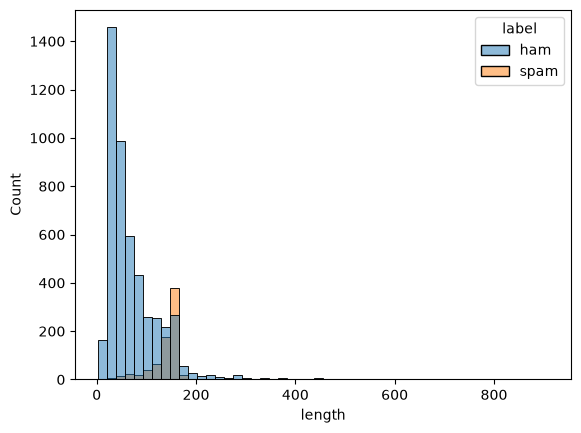

In [77]:
print(df.isnull().sum())
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True))

df["length"] = df["message"].str.len()
print(df.groupby("label")["length"].describe())

sns.histplot(data=df, x="length", hue="label", bins=50)
plt.show()

In [78]:
df = df.drop_duplicates(subset="message").reset_index(drop=True)
print(df.shape)

df["target"] = df["label"].map({"ham": 0, "spam": 1})

(5169, 3)


In [79]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " urltoken ", text)   # links
    text = re.sub(r"[£$€]\s?\d+[\d,.]*", " moneytoken ", text) # money amounts
    text = re.sub(r"\b\d{5,}\b", " longnumtoken ", text)       # phone numbers / short codes
    text = re.sub(r"[^a-z\s]", " ", text)                      # keep letters only
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean"] = df["message"].apply(clean_text)
print(df[["message", "clean"]].head())

                                             message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                               clean  
0  go until jurong point crazy available only in ...  
1                            ok lar joking wif u oni  
2  free entry in a wkly comp to win fa cup final ...  
3        u dun say so early hor u c already then say  
4  nah i don t think he goes to usf he lives arou...  


In [80]:
X = df["clean"]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(4135,) (1034,)


In [81]:
def make_pipe(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                                  min_df=2, sublinear_tf=True)),
        ("clf", clf),
    ])

models = {
    "Naive Bayes": make_pipe(MultinomialNB(alpha=0.1)),
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=1000, C=10,
                                                        class_weight="balanced")),
    "Linear SVM": make_pipe(LinearSVC(C=1.0, class_weight="balanced")),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
    print(f"{name}: F1 = {scores.mean():.3f} (+/- {scores.std():.3f})")

Naive Bayes: F1 = 0.946 (+/- 0.013)
Logistic Regression: F1 = 0.951 (+/- 0.013)
Linear SVM: F1 = 0.950 (+/- 0.012)


In [82]:
rows = []
preds = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    preds[name] = pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).round(3)
print(results.to_string(index=False))

              Model  Accuracy  Precision  Recall    F1
        Naive Bayes     0.988      0.976   0.931 0.953
Logistic Regression     0.986      0.961   0.931 0.946
         Linear SVM     0.986      0.968   0.924 0.945


Best model: Naive Bayes
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       903
        Spam       0.98      0.93      0.95       131

    accuracy                           0.99      1034
   macro avg       0.98      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



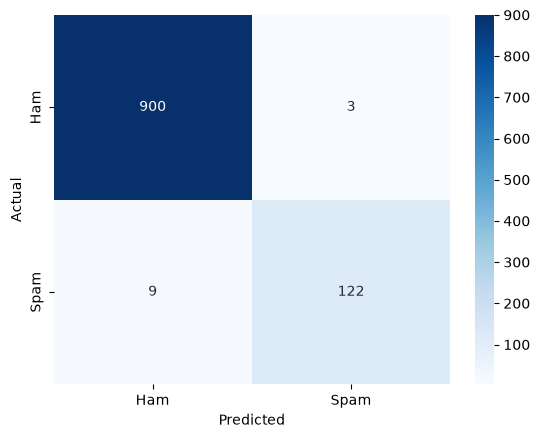

In [83]:
best_name = results.sort_values("F1", ascending=False).iloc[0]["Model"]
best_model = models[best_name]
print("Best model:", best_name)

print(classification_report(y_test, preds[best_name], target_names=["Ham", "Spam"]))

cm = confusion_matrix(y_test, preds[best_name])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [84]:
test_df = pd.DataFrame({"message": df.loc[X_test.index, "message"],
                        "actual": y_test, "predicted": preds[best_name]})

print("Missed spam (false negatives):")
print(test_df[(test_df.actual == 1) & (test_df.predicted == 0)].head(5).to_string())

print("\nLegit flagged as spam (false positives):")
print(test_df[(test_df.actual == 0) & (test_df.predicted == 1)].head(5).to_string())

Missed spam (false negatives):
                                                                                                                                                               message  actual  predicted
2906               Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna chat xxSP visionsms.com Text stop to stopCost 150p 08712400603       1          0
5139  ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT. BAILIFF DUE IN DAYS. I O å£250 3 WANT å£800       1          0
660                                                                                                                         SMS. ac sun0819 posts HELLO:\You seem cool       1          0
2302          Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs)       1          0
4497                                   

In [85]:
lr = models["Logistic Regression"]
words = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coefs = lr.named_steps["clf"].coef_[0]

print("Top spam words:", words[np.argsort(coefs)[-15:]][::-1])
print("Top ham words: ", words[np.argsort(coefs)[:15]])

Top spam words: ['longnumtoken' 'urltoken' 'moneytoken' 'mobile' 'reply' 'txt' 'arsenal'
 'freephone' 'won' 'tf' 'text' 'claim' 'tones' 'uk' 'stop']
Top ham words:  ['ok' 'home' 'lt' 'ring' 'ring ur' 'gt' 'got' 'lt gt' 'da' 'mail' 'll'
 'later' 'lol' 'morning' 'lor']


In [86]:
def predict_sms(text, model=best_model):
    pred = model.predict([clean_text(text)])[0]
    return "SPAM" if pred == 1 else "HAM (legitimate)"

print(predict_sms("Congratulations! You won a £1000 prize. Call 09061701461 to claim now"))
print(predict_sms("Hey, are we still meeting for lunch at 1?"))
print(predict_sms("URGENT! Your account is suspended. Click http://bit.ly/xyz to verify"))

SPAM
HAM (legitimate)
SPAM


In [87]:
joblib.dump(best_model, "sms_spam_model.pkl", compress=3)

# Later, in another script:
# model = joblib.load("sms_spam_model.pkl")
# model.predict([clean_text("Win a free iPhone now!")])

['sms_spam_model.pkl']